# 17 Does explicit motion help? ST-GCN with velocity channels

**Why this test.** The cross model error analysis (notebook 16) found that the errors every model shares are
between shots that differ in speed or swing amplitude: Tap Smash against Smash, Push Shot against Lift, Clear
against Lift. The dataset already computes the frame to frame velocity of every joint, but no model has used
it. ST-GCN can in principle recover velocity from positions through its temporal convolutions, but giving it
explicitly is the cheapest possible test of whether motion information is being under used, and it settles
whether a model 5 built around motion is worth designing.

**One change only.** The final ST-GCN configuration (`body_court`, tuned recipe, advanced augmentation,
balanced sampler), with two extra input channels per joint: the velocity (dx, dy per frame, in body height
units). Everything else is identical to the headline ST-GCN runs of notebook 06, which are reused as the
baseline (same seeds 42, 123, 7). Velocity is multiplied by one fixed constant computed from training clips so
that its magnitude is comparable to the other channels.

**How velocity is computed.** Not as the raw frame to frame difference stored in the dataset. The noise
augmentation adds independent noise to every frame, and differencing frames turns that into velocity of about
the same size as real motion, so training clips would carry noisy velocity while validation and test clips would
not. Velocity here is a 5 frame Savitzky-Golay derivative of the (augmented) keypoints, applied identically at
training and test time, which cuts that noise by about 4.5 times. The smoke test checks that training and
validation clips end up with matching velocity statistics.

**Decision rule, fixed before running, on validation.** Velocity counts as helping if mean validation top 1 is
at least 0.5 points above the baseline and mean validation MCA is not more than 1 point lower. Test results are
shown for reporting but do not drive the decision, the same discipline as the tuning notebooks.

**Targeted check.** Beyond the aggregate, the six confusions named above are compared directly. If velocity
carries the missing information, those rates should fall; if they do not, the speed hypothesis is wrong even if
aggregate metrics move.

Logs to `BadmintonPoseAnalysis/experiments/velocity_input`.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import glob
import json
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy import stats
from sklearn.metrics import f1_score, precision_recall_fscore_support
from clearml import Task

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
sys.path.insert(0, REPO)
import dataset as ds
from models import stgcn as stgcn_model
import training as tr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/experiments/velocity_input"
KEYPOINTS = f"{DATA}/keypoints_interp"
OUT = f"{OUTPUTS}/experiments/velocity_input"
os.makedirs(OUT, exist_ok=True)

SEEDS = [42, 123, 7]
SPLITS = ("train", "val", "test")
NORMALISATION, USE_COURT, USE_VELOCITY = "body", True, True
NUM_WORKERS, EVAL_WORKERS = 20, 8
RARE_THRESHOLD = int(os.environ.get("RARE_THRESHOLD", 150))
MIN_GAIN, MAX_MCA_DROP = 0.005, 0.01

with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)
print("recipe:", RECIPE)

recipe: {'model': 'ST-GCN', 'normalisation': 'body_court', 'selected': 'combination', 'changes_from_baseline': {'weight_decay': 0.005, 'target_per_class': 300}, 'augmentation': 'advanced', 'min_native_frames': 5, 'batch_size': 16, 'lr': 0.01, 'momentum': 0.9, 'gamma': 0.1, 'select_metric': 'top1', 'weight_decay': 0.005, 'label_smoothing': 0.0, 'schedule': 'step10', 'target_per_class': 300, 'num_epochs': 60, 'patience': 20, 'tuning': {'seeds': [11, 22], 'val_top1': 0.7612, 'baseline_val_top1': 0.7394}}


In [3]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
K = len(class_names)
short = [c.split("_", 1)[1] for c in class_names]
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]
train = manifest[manifest["split"] == "train"].reset_index(drop=True)
train_counts = train["class_name"].value_counts().reindex(class_names)
rare_ids = [class_to_id[c] for c in class_names if train_counts[c] < RARE_THRESHOLD]

# one fixed constant, from training clips only, so velocity has a magnitude comparable to the other channels
probe = ds.BadmintonPoseDataset(train.sample(min(600, len(train)), random_state=0), KEYPOINTS, class_to_id, "none", NORMALISATION)
clean_xy = torch.stack([probe[i]["keypoints"][..., :2] for i in range(len(probe))])        # (n, T, V, 2), no augmentation
VEL_SCALE = float(1.0 / stgcn_model.smoothed_velocity(clean_xy).std())
print(f"smoothed velocity std {1 / VEL_SCALE:.4f} body heights per frame on clean training clips -> scale {VEL_SCALE:.1f}")

in_channels = stgcn_model.n_channels(USE_COURT, USE_VELOCITY)
forward = stgcn_model.make_forward(USE_COURT, USE_VELOCITY, VEL_SCALE)

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
smoothed velocity std 0.0347 body heights per frame on clean training clips -> scale 28.8


## Smoke test

Run alone first. Prints the mean and spread of every input channel (velocity should now be of the same order
as the others), checks one forward and backward pass, and confirms the baseline predictions needed for the
comparison are present before any training time is spent.

In [4]:
tr.seed_everything(0)
loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, RECIPE["augmentation"], NORMALISATION, seed=0,
                           batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                           num_workers=2, eval_workers=2)
model = stgcn_model.build_stgcn(in_channels, K).to(device)
batch = next(iter(loaders["train"]))

vel_train = stgcn_model.smoothed_velocity(batch["keypoints"][..., :2].float()) * VEL_SCALE
channels = torch.cat([batch["keypoints"], batch["bone"], batch["court"][:, :, None, :].expand(-1, -1, 17, -1),
                      vel_train], dim=-1).float()
names = ["x", "y", "confidence", "bone dx", "bone dy", "court x", "court y", "velocity dx", "velocity dy"]
print(pd.DataFrame({"mean": channels.mean(dim=(0, 1, 2)).numpy(), "std": channels.std(dim=(0, 1, 2)).numpy()},
                   index=names).round(3).T.to_string())

# training (augmented) and validation (clean) velocity must have matching statistics
val_ds = ds.BadmintonPoseDataset(manifest[manifest["split"] == "val"].head(200), KEYPOINTS, class_to_id, "none", NORMALISATION)
vel_val = stgcn_model.smoothed_velocity(torch.stack([val_ds[i]["keypoints"][..., :2] for i in range(len(val_ds))])) * VEL_SCALE
ratio = float(vel_train.std() / vel_val.std())
print(f"velocity std, augmented training batch {vel_train.std():.2f} vs clean validation clips {vel_val.std():.2f} (ratio {ratio:.2f})")
assert 0.7 < ratio < 1.4, "training and validation velocity statistics differ too much"

logits = forward(model, batch, device)
assert logits.shape == (RECIPE["batch_size"], K)
nn.CrossEntropyLoss()(logits, batch["label"].to(device)).backward()
assert not [n for n, p in model.named_parameters() if p.requires_grad and p.grad is None]
print(f"{in_channels} input channels, {sum(p.numel() for p in model.parameters()):,} parameters")
del model, loaders

RUN_RE = re.compile(r"^stgcn_advanced_s(\d+)$")
baseline_paths = {}
for p in glob.glob(f"{OUTPUTS}/models/**/*_predictions.csv", recursive=True):
    m = RUN_RE.match(os.path.basename(p).replace("_predictions.csv", ""))
    if m and int(m.group(1)) in SEEDS:
        baseline_paths[int(m.group(1))] = p
assert sorted(baseline_paths) == sorted(SEEDS), f"baseline ST-GCN predictions found for seeds {sorted(baseline_paths)}"
print("baseline predictions found for seeds", sorted(baseline_paths))
print("smoke test passed")

          x      y  confidence  bone dx  bone dy  court x  court y  velocity dx  velocity dy
mean -0.018 -0.148       0.658    0.003    0.136    0.526    0.470       -0.692        0.006
std   0.407  0.332       0.139    0.131    0.129    0.098    0.035        1.065        0.551
velocity std, augmented training batch 0.92 vs clean validation clips 0.91 (ratio 1.01)
9 input channels, 3,028,735 parameters
baseline predictions found for seeds [7, 42, 123]
smoke test passed


## Runs

Three seeds. Results are appended after every run and finished runs are skipped.

In [5]:
results_path = f"{OUT}/results.csv"
done = pd.read_csv(results_path) if os.path.exists(results_path) else pd.DataFrame(columns=["seed"])

for seed in SEEDS:
    if (done["seed"] == seed).any():
        print(f"skip seed {seed}, already done")
        continue
    run_name = f"stgcn_velocity_s{seed}"
    print(f"\n=== {run_name} ===")
    tr.seed_everything(seed)

    task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                     tags=["velocity_input", "stgcn", f"seed{seed}"], reuse_last_task_id=False,
                     auto_connect_frameworks={"matplotlib": False, "pytorch": False})
    task.connect({**RECIPE, "input": "body_court_velocity", "in_channels": in_channels, "velocity_scale": VEL_SCALE,
                  "seed": seed, "keypoints": KEYPOINTS, "split_sha256": split_hash})

    loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, RECIPE["augmentation"], NORMALISATION, seed=seed,
                               batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                               num_workers=NUM_WORKERS, eval_workers=EVAL_WORKERS)
    model = stgcn_model.build_stgcn(in_channels, K).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=RECIPE["lr"], momentum=RECIPE["momentum"],
                                weight_decay=RECIPE["weight_decay"])
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=RECIPE["gamma"])
    criterion = nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])

    _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device,
                                            task.get_logger(), num_epochs=RECIPE["num_epochs"],
                                            patience=RECIPE.get("patience", 20), select_metric=RECIPE["select_metric"],
                                            splits=SPLITS)
    metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                            out_dir=f"{OUT}/{run_name}", run_name=run_name, splits=SPLITS, show=False,
                            extra={"seed": seed, "input": "body_court_velocity"})
    task.close()

    done = pd.concat([done, pd.DataFrame([metrics])], ignore_index=True)
    done.to_csv(results_path, index=False)
    del model, loaders
    torch.cuda.empty_cache()


=== stgcn_velocity_s42 ===
ClearML Task: created new task id=ff01f3cf93034298a5cebbc112b5434b
2026-10-06 11:05:03,627 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/de73ee9c3d4e40ef8619cedc5e38f40e/tasks/ff01f3cf93034298a5cebbc112b5434b/output/log
epoch   0  loss 1.909  train 0.576  val 0.557 (mca 0.413)  *
epoch   1  loss 1.490  train 0.644  val 0.621 (mca 0.490)  *
epoch   2  loss 1.358  train 0.656  val 0.644 (mca 0.548)  *
epoch   3  loss 1.280  train 0.662  val 0.648 (mca 0.534)  *
epoch   4  loss 1.223  train 0.710  val 0.676 (mca 0.540)  *
epoch   5  loss 1.184  train 0.696  val 0.679 (mca 0.563)  *
epoch   9  loss 1.138  train 0.711  val 0.685 (mca 0.614)  *
epoch  10  loss 0.882  train 0.784  val 0.726 (mca 0.648)  *
epoch  12  loss 0.756  train 0.810  val 0.739 (mca 0.654)  *
epoch  15  loss 0.640  train 0.847  val 0.725 (mca 0.653)
epoch  20  loss 0.434  train 0.911  val 0.745 (mca 0.

███████████████████████████████ 100% | 11.66/11.66 MB [00:01<00:00,  6.92MB/s]: 



=== stgcn_velocity_s123 ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=eecc092c0dde4f0cb68f7a8492928255
ClearML results page: https://app.clear.ml/projects/de73ee9c3d4e40ef8619cedc5e38f40e/tasks/eecc092c0dde4f0cb68f7a8492928255/output/log
epoch   0  loss 1.935  train 0.557  val 0.576 (mca 0.415)  *
epoch   1  loss 1.486  train 0.625  val 0.622 (mca 0.468)  *
epoch   3  loss 1.267  train 0.673  val 0.666 (mca 0.577)  *
epoch   4  loss 1.215  train 0.711  val 0.700 (mca 0.618)  *
epoch   5  loss 1.195  train 0.691  val 0.682 (mca 0.596)
epoch  10  loss 0.901  train 0.782  val 0.726 (mca 0.633)  *
epoch  11  loss 0.814  train 0.797  val 0.731 (mca 0.641)  *
epoch  14  loss 0.676  train 0.828  val 0.734 (mca 0.644)  *
epoch  15  loss 0.636  train 0.841  val 0.732 (mca 0.643)
epoch  20  loss 0.436  train 0.916  val 0.727 (mca 0.638)
epoch  21  loss 0.390  train 0.924  val 0.740 (mca 0.653)  *
epoch  22  loss 0.367  train 0.930  val 0.744 (mca 0.652)  *
epoch  25  loss 0.334  train 0.947  val 0.752 (mca 0.660)  *
epoch  30  los

███████████████████████████████ 100% | 11.66/11.66 MB [00:01<00:00,  7.24MB/s]: 



=== stgcn_velocity_s7 ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=392d82350a54457597dcd5d18eec0e62
ClearML results page: https://app.clear.ml/projects/de73ee9c3d4e40ef8619cedc5e38f40e/tasks/392d82350a54457597dcd5d18eec0e62/output/log
epoch   0  loss 1.969  train 0.581  val 0.575 (mca 0.417)  *
epoch   1  loss 1.536  train 0.618  val 0.620 (mca 0.528)  *
epoch   3  loss 1.290  train 0.688  val 0.691 (mca 0.580)  *
epoch   5  loss 1.179  train 0.668  val 0.627 (mca 0.538)
epoch  10  loss 0.891  train 0.783  val 0.725 (mca 0.637)  *
epoch  11  loss 0.791  train 0.805  val 0.736 (mca 0.636)  *
epoch  15  loss 0.654  train 0.832  val 0.723 (mca 0.623)
epoch  18  loss 0.579  train 0.866  val 0.741 (mca 0.646)  *
epoch  20  loss 0.456  train 0.906  val 0.741 (mca 0.641)
epoch  23  loss 0.365  train 0.931  val 0.743 (mca 0.645)  *
epoch  24  loss 0.356  train 0.932  val 0.750 (mca 0.657)  *
epoch  25  loss 0.337  train 0.941  val 0.744 (mca 0.655)
epoch  28  loss 0.309  train 0.950  val 0.755 (mca 0.662)  *
epoch  30  loss 0

███████████████████████████████ 100% | 11.66/11.66 MB [00:01<00:00,  6.39MB/s]: 


## Comparison with the baseline

Both arms are read from per clip predictions, so the baseline (notebook 06 runs, same seeds) and the velocity
runs are treated identically.

In [6]:
def read(path, split):
    p = pd.read_csv(path)
    p = p[p["split"] == split].sort_values("filepath").reset_index(drop=True)
    return {"label": p["label"].map(class_to_id).to_numpy(), "pred": p["pred"].map(class_to_id).to_numpy(),
            "top5": np.array([l in str(t).split(";") for l, t in zip(p["label"], p["top5"].fillna(""))])}


arm_paths = {"baseline": baseline_paths,
             "velocity": {s: f"{OUT}/stgcn_velocity_s{s}/stgcn_velocity_s{s}_predictions.csv" for s in SEEDS}}
runs = {(arm, split): [read(arm_paths[arm][s], split) for s in SEEDS] for arm in arm_paths for split in ("val", "test")}


def metric_rows(arm, split):
    rows = []
    for r in runs[(arm, split)]:
        rec = np.array([(r["pred"][r["label"] == k] == k).mean() for k in range(K)])
        rows.append({"top1": (r["pred"] == r["label"]).mean(), "top5": r["top5"].mean(), "mca": rec.mean(),
                     "macro_f1": f1_score(r["label"], r["pred"], average="macro", labels=list(range(K)), zero_division=0),
                     "limited sample recall": rec[rare_ids].mean()})
    return pd.DataFrame(rows)


def welch(a, b):
    d = a.mean() - b.mean()
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    se = np.sqrt(va + vb)
    df = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1)) if se > 0 else 1
    h = stats.t.ppf(0.975, df) * se
    return d, d - h, d + h


task_s = Task.init(project_name=PROJECT, task_name="velocity_summary", task_type=Task.TaskTypes.qc,
                   tags=["velocity_input", "summary"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
slog = task_s.get_logger()
task_s.connect({**RECIPE, "seeds": SEEDS, "velocity_scale": VEL_SCALE, "rule": {"min_gain": MIN_GAIN, "max_mca_drop": MAX_MCA_DROP}})

rows = []
mt = {}
for split in ("val", "test"):
    for arm in ("baseline", "velocity"):
        mt[(arm, split)] = metric_rows(arm, split)
    for m in ["top1", "top5", "mca", "macro_f1", "limited sample recall"]:
        a, b = mt[("velocity", split)][m], mt[("baseline", split)][m]
        d, lo, hi = welch(a, b)
        rows.append({"split": split, "metric": m, "baseline": f"{100 * b.mean():.2f} ± {100 * b.std(ddof=1):.2f}",
                     "with velocity": f"{100 * a.mean():.2f} ± {100 * a.std(ddof=1):.2f}",
                     "difference (points)": f"{100 * d:+.2f}", "seeds only 95% CI": f"[{100 * lo:+.1f}, {100 * hi:+.1f}]"})
table = pd.DataFrame(rows)
slog.report_table("velocity vs baseline", "comparison", iteration=0, table_plot=table)

dv_top1 = mt[("velocity", "val")]["top1"].mean() - mt[("baseline", "val")]["top1"].mean()
dv_mca = mt[("velocity", "val")]["mca"].mean() - mt[("baseline", "val")]["mca"].mean()
helps = dv_top1 >= MIN_GAIN and dv_mca >= -MAX_MCA_DROP
print(f"validation: top1 {100 * dv_top1:+.2f}, MCA {100 * dv_mca:+.2f} -> velocity {'HELPS' if helps else 'does not help'} under the rule")
slog.report_single_value("val_top1_difference_points", 100 * dv_top1)
slog.report_single_value("val_mca_difference_points", 100 * dv_mca)
table

Failed accessing the jupyter server(s): []


ClearML Task: created new task id=2b8275eaee1840028a9cbc24b267b525
ClearML results page: https://app.clear.ml/projects/de73ee9c3d4e40ef8619cedc5e38f40e/tasks/2b8275eaee1840028a9cbc24b267b525/output/log
validation: top1 +1.20, MCA +2.27 -> velocity HELPS under the rule


,split,metric,baseline,with velocity,difference (points),seeds only 95% CI
0,val,top1,74.78 ± 0.13,75.97 ± 0.20,+1.20,"[+0.8, +1.6]"
1,val,top5,94.49 ± 0.56,95.09 ± 0.41,+0.60,"[-0.6, +1.7]"
2,val,mca,64.73 ± 0.78,67.00 ± 0.86,+2.27,"[+0.4, +4.1]"
3,val,macro_f1,65.49 ± 1.02,67.79 ± 0.61,+2.31,"[+0.2, +4.4]"
4,val,limited sample recall,58.62 ± 2.45,60.93 ± 2.30,+2.31,"[-3.1, +7.7]"
5,test,top1,72.29 ± 1.06,73.15 ± 1.45,+0.85,"[-2.1, +3.8]"
6,test,top5,94.37 ± 0.13,94.46 ± 0.15,+0.09,"[-0.2, +0.4]"
7,test,mca,61.21 ± 1.33,60.98 ± 1.06,-0.23,"[-3.0, +2.5]"
8,test,macro_f1,62.31 ± 1.94,62.86 ± 0.92,+0.56,"[-3.5, +4.6]"
9,test,limited sample recall,52.18 ± 2.54,49.58 ± 3.93,-2.60,"[-10.6, +5.4]"


In [7]:
PAIRS = [("Push Shot", "Lift"), ("Lift", "Push Shot"), ("Flat Shot", "Lift"), ("Tap Smash", "Smash"),
         ("Clear", "Lift"), ("Smash", "Cut")]


def pair_rate(arm, a, b, split="test"):
    ia, ib = short.index(a), short.index(b)
    vals = []
    for r in runs[(arm, split)]:
        m = r["label"] == ia
        vals.append((r["pred"][m] == ib).mean())
    return 100 * np.mean(vals), 100 * np.std(vals, ddof=1)


rows = []
for a, b in PAIRS:
    (rb, sb), (rv, sv) = pair_rate("baseline", a, b), pair_rate("velocity", a, b)
    rows.append({"confusion": f"{a} predicted as {b}", "baseline rate (%)": f"{rb:.1f} ± {sb:.1f}",
                 "with velocity (%)": f"{rv:.1f} ± {sv:.1f}", "change (points)": f"{rv - rb:+.1f}"})
pair_table = pd.DataFrame(rows)
slog.report_table("targeted confusions, test", "comparison", iteration=0, table_plot=pair_table)
pair_table

,confusion,baseline rate (%),with velocity (%),change (points)
0,Push Shot predicted as Lift,30.0 ± 2.5,31.7 ± 3.8,+1.7
1,Lift predicted as Push Shot,14.0 ± 4.0,14.0 ± 5.5,+0.0
2,Flat Shot predicted as Lift,22.9 ± 1.8,17.7 ± 6.5,-5.2
3,Tap Smash predicted as Smash,51.5 ± 5.2,48.5 ± 5.2,-3.0
4,Clear predicted as Lift,8.4 ± 1.1,6.3 ± 1.8,-2.1
5,Smash predicted as Cut,8.1 ± 0.7,3.7 ± 0.0,-4.5


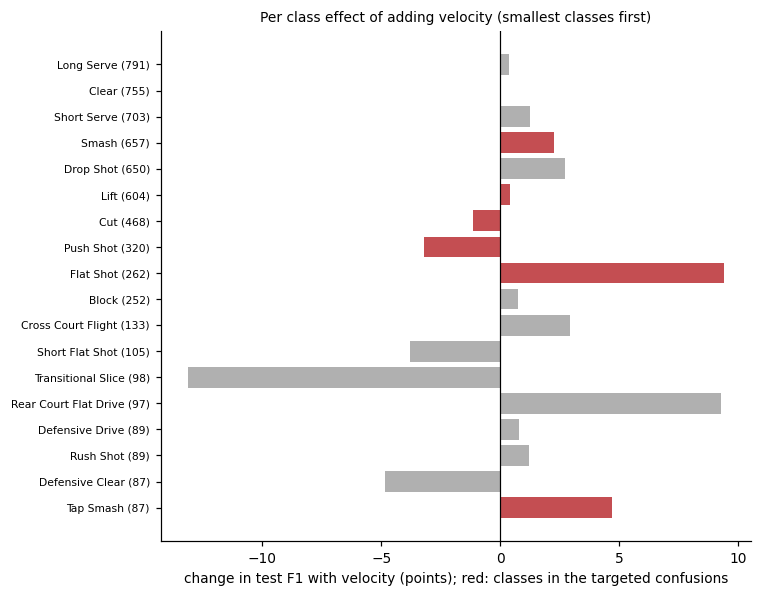

In [8]:
def per_class_f1(arm, split="test"):
    out = []
    for r in runs[(arm, split)]:
        _, _, f, _ = precision_recall_fscore_support(r["label"], r["pred"], labels=list(range(K)), zero_division=0)
        out.append(f)
    return np.mean(out, axis=0)


delta = per_class_f1("velocity") - per_class_f1("baseline")
order = np.argsort(train_counts.to_numpy())
named = {x for pair in PAIRS for x in pair}
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(range(K), 100 * delta[order], color=["#c44e52" if short[i] in named else "#b0b0b0" for i in order])
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(K), [f"{short[i]} ({train_counts.iloc[i]})" for i in order], fontsize=7)
ax.set_xlabel("change in test F1 with velocity (points); red: classes in the targeted confusions")
ax.set_title("Per class effect of adding velocity (smallest classes first)", fontsize=9)
fig.tight_layout()
slog.report_matplotlib_figure("per class change with velocity", "comparison", figure=fig, iteration=0, report_interactive=False)
plt.show()
task_s.upload_artifact("results", artifact_object=results_path)
task_s.close()

## Reading the result

- Apply the stated rule to the validation difference printed above. If velocity helps, the next step is a
  model 5 built around motion (for example multi scale temporal modelling and a speed aware head), with this
  result as its baseline. If it does not, explicit velocity adds nothing ST-GCN has not already learned, and
  model 5 needs a different justification.
- Read the targeted confusions separately from the aggregate. A fall in the speed related confusions with
  little change in the aggregate would still support the hypothesis; an aggregate gain without any fall in
  those confusions would mean velocity is helping for some other reason.
- With three seeds the intervals are wide. Treat differences of a point or less as unresolved.